# SINDy y Weak-SINDy: identificación y búsqueda reproducible
## Sistema liebre–lince 

Este notebook reúne dos objetivos:

1. **explicar cómo funcionan SINDy clásico y Weak-SINDy** sobre los mismos 21 datos;
2. **mostrar cómo se encontró la configuración seleccionada**, en lugar de presentar sus hiperparámetros como números elegidos a posteriori.

La lógica experimental será la misma en ambos métodos:

$$
\text{biblioteca candidata}
\rightarrow
\text{familia de configuraciones}
\rightarrow
\text{ajuste}
\rightarrow
\text{soporte}
\rightarrow
\text{integración}
\rightarrow
\text{métricas}
\rightarrow
\text{selección}.
$$

En Weak-SINDy se reproduce la búsqueda original de refinamiento: **14 040 ajustes STLSQ** y, cuando `SR3` está disponible, **90 ajustes SR3 selectivos**, para un máximo de **14 130 configuraciones**. En el experimento original con PySINDy 2.1.0 aparecieron **72 modelos con soporte exactamente tipo Lotka–Volterra**.

En SINDy clásico se realiza una búsqueda análoga, pero **no se fuerza artificialmente el mismo número de configuraciones**: SINDy clásico tiene menos hiperparámetros que Weak-SINDy. Esto es metodológicamente importante.

## 1. Dependencias y reproducibilidad

In [20]:
# Si hace falta:
# %pip install "pysindy>=2.0,<3" numpy pandas scipy matplotlib scikit-learn

from __future__ import annotations
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pysindy as ps

print("PySINDy:", ps.__version__)
print("STLSQ:", inspect.signature(ps.STLSQ))
print("SR3 disponible:", hasattr(ps, "SR3"))

PySINDy: 2.0.0
STLSQ: (threshold=0.1, alpha=0.05, max_iter=20, ridge_kw=None, normalize_columns=False, copy_X=True, initial_guess=None, verbose=False, sparse_ind=None, unbias=True)
SR3 disponible: True


## 2. Datos

Las observaciones son anuales, 1900--1920. Para el cálculo usamos
$t=0,\ldots,20$ y $\Delta t=1$. No se crean observaciones por interpolación.

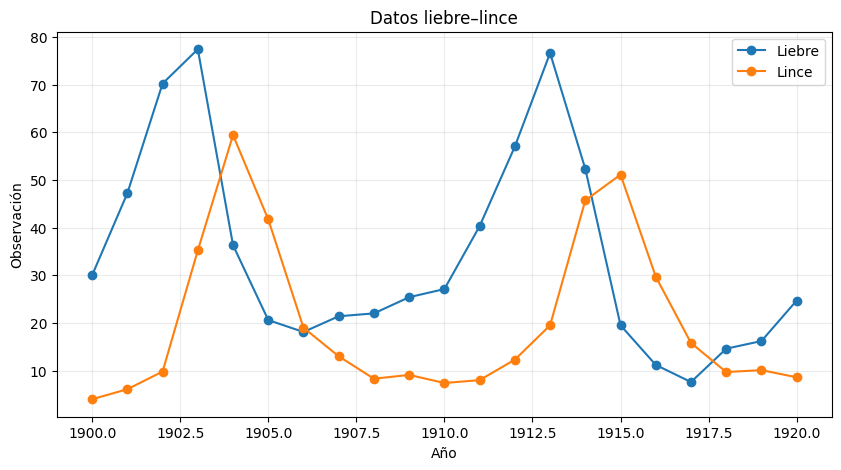

In [21]:
years = np.arange(1900, 1921, dtype=int)
hare = np.array([30.0,47.2,70.2,77.4,36.3,20.6,18.1,21.4,22.0,25.4,27.1,
                 40.3,57.0,76.6,52.3,19.5,11.2,7.6,14.6,16.2,24.7])
lynx = np.array([4.0,6.1,9.8,35.2,59.4,41.7,19.0,13.0,8.3,9.1,7.4,
                 8.0,12.3,19.5,45.7,51.1,29.7,15.8,9.7,10.1,8.6])

t = np.arange(21, dtype=float)
dt = 1.0
X = np.column_stack([hare, lynx])
feature_names = ["x","y"]
physical_feature_names = {"1","x","y","x^2","x*y","y^2"}

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(years,hare,"o-",label="Liebre")
ax.plot(years,lynx,"o-",label="Lince")
ax.set(xlabel="Año",ylabel="Observación",title="Datos liebre–lince")
ax.legend(); ax.grid(alpha=.25); plt.show()

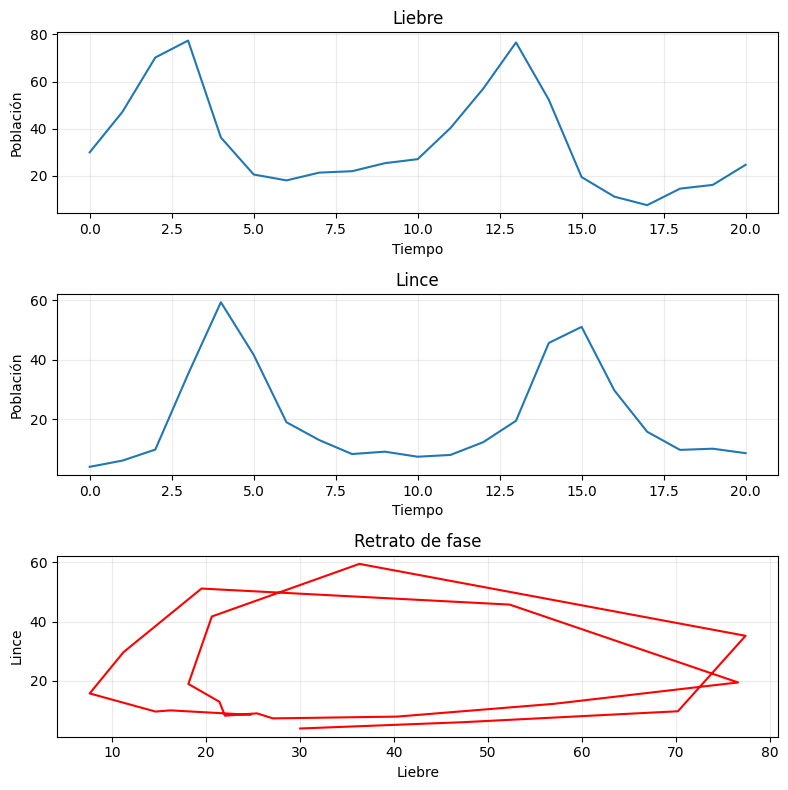

In [22]:
# Gráficas del sistema Presa–Depredador
plt.figure(figsize=(8, 8))

# Evolución de la Presa
plt.subplot(3, 1, 1)
plt.plot(t, hare)
plt.title("Liebre")
plt.xlabel("Tiempo")
plt.ylabel("Población")
plt.grid(alpha=0.25)

# Evolución del Depredador
plt.subplot(3, 1, 2)
plt.plot(t, lynx)
plt.title("Lince")
plt.xlabel("Tiempo")
plt.ylabel("Población")
plt.grid(alpha=0.25)

# Retrato de fase
plt.subplot(3, 1, 3)
plt.plot(hare, lynx, 'r')
plt.title("Retrato de fase")
plt.xlabel("Liebre")
plt.ylabel("Lince")
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 3. Biblioteca común y criterio de ``soporte tipo Lotka--Volterra''

En ambos métodos usamos la misma biblioteca polinómica

$$
\Theta(x,y)=[1,x,y,x^2,xy,y^2].
$$

Decimos que un modelo tiene **soporte exactamente tipo Lotka-Volterra** cuando

$$
\dot x:\{x,xy\},\qquad
\dot y:\{y,xy\}.
$$

Esta definición evalúa la **estructura algebraica**, no presupone que Lotka-Volterra sea el modelo ecológico verdadero. También registraremos si los cuatro signos son los esperados:

$$
x>0,\quad xy<0 \quad\text{en }\dot x,
\qquad
y<0,\quad xy>0 \quad\text{en }\dot y.
$$

In [23]:
def canonicalize_name(name):
    v = name.replace(" ","").replace("x0","x").replace("x1","y")
    v = v.replace("x**2","x^2").replace("y**2","y^2").replace("xy","x*y")
    return v if v else "1"

def support_tuple(coef,names,eq,tol=1e-12):
    return tuple(names[j] for j in range(len(names)) if abs(coef[eq,j])>tol)

def lv_scores(coef,names):
    idx={n:i for i,n in enumerate(names)}
    sx=set(support_tuple(coef,names,0)); sy=set(support_tuple(coef,names,1))
    ex={"x","x*y"}; ey={"y","x*y"}
    support_score=len(ex & sx)+len(ey & sy)
    sign_score=0
    if "x" in idx: sign_score += int(coef[0,idx["x"]]>0)
    if "y" in idx: sign_score += int(coef[1,idx["y"]]<0)
    if "x*y" in idx:
        sign_score += int(coef[0,idx["x*y"]]<0)
        sign_score += int(coef[1,idx["x*y"]]>0)
    exact=int(sx==ex and sy==ey)
    return support_score,sign_score,exact

def global_r2(obs,pred):
    rss=np.sum((obs-pred)**2)
    tss=np.sum((obs-obs.mean(axis=0,keepdims=True))**2)
    return 1-rss/tss

def library_vector(state,names):
    x,y=map(float,state)
    vals={"1":1.0,"x":x,"y":y,"x^2":x*x,"x*y":x*y,"y^2":y*y}
    return np.array([vals[n] for n in names])

def safe_simulate(coef,names,times,x0):
    try:
        if not np.all(np.isfinite(coef)) or np.max(np.abs(coef))>1000:
            return False,None
        def rhs(_,state):
            if np.max(np.abs(state))>250 or np.min(state)<-5:
                raise FloatingPointError
            val=coef @ library_vector(state,names)
            if not np.all(np.isfinite(val)) or np.max(np.abs(val))>2000:
                raise FloatingPointError
            return val
        sol=solve_ivp(rhs,(float(times[0]),float(times[-1])),x0,t_eval=times,
                      rtol=1e-6,atol=1e-8,max_step=.25)
        if not sol.success or sol.y.shape[1]!=len(times): return False,None
        Y=sol.y.T
        if not np.all(np.isfinite(Y)) or np.max(np.abs(Y))>250 or np.min(Y)<-5:
            return False,None
        return True,Y
    except Exception:
        return False,None

def summarize_fit(coef,names):
    ss,sg,ex=lv_scores(coef,names)
    ok,Y=safe_simulate(coef,names,t,X[0])
    rmse=np.sqrt(np.mean((Y-X)**2)) if ok else np.inf
    r2=global_r2(X,Y) if ok else -np.inf
    return dict(n_active_total=int(np.count_nonzero(np.abs(coef)>1e-12)),
                support_hare="|".join(support_tuple(coef,names,0)),
                support_lynx="|".join(support_tuple(coef,names,1)),
                lv_support_score=ss,lv_sign_score=sg,exact_lv_support=ex,
                trajectory_success=ok,trajectory_rmse=float(rmse),trajectory_r2=float(r2))

# PARTE A — SINDy clásico

## 4. ¿Qué cambia en SINDy clásico?

SINDy clásico necesita una estimación puntual de \(\dot X\):

$$
\dot X\approx\Theta(X)\Xi.
$$

Con solo 21 observaciones anuales, la diferenciación numérica es una parte sensible del procedimiento. En esta comparación docente mantenemos fija la diferenciación predeterminada de PySINDy y exploramos sistemáticamente los hiperparámetros de STLSQ.

La búsqueda clásica no tiene $K,H_{xt},p$, porque esos parámetros pertenecen a la formulación débil.

In [24]:
classic_thresholds=np.unique(np.r_[0.0,np.logspace(-3,3,25)]).tolist()
classic_alphas=[1e-10,1e-8,1e-6]
classic_normalize=[True,False]

classic_total=len(classic_thresholds)*len(classic_alphas)*len(classic_normalize)
print("Configuraciones SINDy clásico:",classic_total)
print(len(classic_thresholds))
print(len(classic_alphas))

Configuraciones SINDy clásico: 156
26
3


In [25]:
def fit_classic_sindy(threshold,alpha,normalize_columns):
    lib=ps.PolynomialLibrary(degree=2,include_bias=True,interaction_only=False)
    opt=ps.STLSQ(threshold=float(threshold),alpha=float(alpha),
                 normalize_columns=bool(normalize_columns),max_iter=200)
    model=ps.SINDy(differentiation_method=ps.FiniteDifference(order=4,drop_endpoints=True),feature_library=lib,optimizer=opt)
    model.fit(X,t=dt,feature_names=feature_names)
    coef=np.asarray(model.coefficients(),float)
    names=[canonicalize_name(n) for n in model.get_feature_names()]
    summary=summarize_fit(coef,names)
    return {**summary,"threshold":threshold,"alpha":alpha,
            "normalize_columns":normalize_columns,
            "coefficients":coef,"library_names":names}

## 5. Exploración de SINDy clásico

Cada fila de la tabla siguiente es un experimento reproducible. Así podemos mostrar al jurado que el modelo seleccionado no proviene de probar manualmente un único `threshold`.

In [26]:
classic_experiments=[]
classic_failures=[]

for norm in classic_normalize:
    for alpha in classic_alphas:
        for threshold in classic_thresholds:
            try:
                classic_experiments.append(
                    fit_classic_sindy(threshold,alpha,norm)
                )
            except Exception as e:
                classic_failures.append((threshold,alpha,norm,type(e).__name__))

classic_table=pd.DataFrame([
    {k:v for k,v in e.items() if k not in {"coefficients","library_names"}}
    for e in classic_experiments
])

print("Ajustes exitosos:",len(classic_experiments))
print("Fallos:",len(classic_failures))
print("Soporte LV exacto:",int(classic_table["exact_lv_support"].sum()))
display(classic_table.sort_values(
    ["exact_lv_support","lv_sign_score","lv_support_score","trajectory_rmse"],
    ascending=[False,False,False,True]).head(15))

C:\Users\megar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (100.0) and eliminated all coefficients
  warnings.warn(
C:\Users\megar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pysindy\optimizers\stlsq.py:224: UserWarning: Sparsity parameter is too big (100.0) and eliminated all coefficients
  warnings.warn(
C:\Users\megar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pysindy\optimizers\stlsq.py:234: UserWarning: Sparsity parameter is too big (177.82794100389228) and eliminated all coefficients
  warnings.warn(
C:\Users\megar\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pysindy\optimizers\stlsq.py:224:

Ajustes exitosos: 156
Fallos: 0
Soporte LV exacto: 3


,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,threshold,alpha,normalize_columns
20,4,x|x*y,y|x*y,4,4,1,True,10.806273,0.666800,56.234133,1.000000e-10,True
46,4,x|x*y,y|x*y,4,4,1,True,10.806273,0.666800,56.234133,1.000000e-08,True
72,4,x|x*y,y|x*y,4,4,1,True,10.806273,0.666800,56.234133,1.000000e-06,True
84,8,1|x|y|x*y,1|x|y|x*y,4,4,0,True,10.203499,0.702935,0.017783,1.000000e-10,False
110,8,1|x|y|x*y,1|x|y|x*y,4,4,0,True,10.203499,0.702935,0.017783,1.000000e-08,False
136,8,1|x|y|x*y,1|x|y|x*y,4,4,0,True,10.203499,0.702935,0.017783,1.000000e-06,False
82,9,1|x|y|x*y,1|x|y|x*y|y^2,4,4,0,True,13.179872,0.504350,0.005623,1.000000e-10,False
83,9,1|x|y|x*y,1|x|y|x*y|y^2,4,4,0,True,13.179872,0.504350,0.010000,1.000000e-10,False
108,9,1|x|y|x*y,1|x|y|x*y|y^2,4,4,0,True,13.179872,0.504350,0.005623,1.000000e-08,False
109,9,1|x|y|x*y,1|x|y|x*y|y^2,4,4,0,True,13.179872,0.504350,0.010000,1.000000e-08,False


## 6. Selección transparente en SINDy clásico

Usamos una regla jerárquica explícita:

1. soporte LV exacto;
2. cuatro signos correctos;
3. mayor recuperación de mecanismos LV;
4. menor número de términos;
5. menor RMSE entre los modelos que superaron los criterios anteriores.

El RMSE **no es el primer criterio**.

In [27]:
classic_ok=classic_table[classic_table["trajectory_success"]].copy()
classic_ok["extra_terms"]=classic_ok["n_active_total"]-classic_ok["lv_support_score"]

best_classic_row=classic_ok.sort_values(
    ["exact_lv_support","lv_sign_score","lv_support_score","extra_terms","trajectory_rmse"],
    ascending=[False,False,False,True,True]).iloc[0]

best_classic=next(e for e in classic_experiments
    if np.isclose(e["threshold"],best_classic_row["threshold"])
    and np.isclose(e["alpha"],best_classic_row["alpha"])
    and e["normalize_columns"]==bool(best_classic_row["normalize_columns"]))

display(best_classic_row.to_frame("SINDy seleccionado").T)
print("Coeficientes:\n",best_classic["coefficients"])

,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,threshold,alpha,normalize_columns,extra_terms
SINDy seleccionado,4,x|x*y,y|x*y,4,4,1,True,10.806273,0.6668,56.234133,0.0,True,0


Coeficientes:
 [[ 0.          0.53275474  0.          0.         -0.02476111  0.        ]
 [ 0.          0.         -0.83521672  0.          0.02341899  0.        ]]


# PARTE B — Weak-SINDy

## 7. Forma débil y parámetros adicionales

Weak-SINDy parte de

$$
-\int_{I_k}\dot\phi_k(t)\mathbf{x}(t)\,dt
=
\int_{I_k}\phi_k(t)F(\mathbf{x}(t))\,dt,
$$

y construye un sistema $B\approx G\Xi$. Aparecen entonces parámetros adicionales relacionados con las funciones de prueba y sus ventanas: $K,H_{xt},p$.

Por eso la búsqueda Weak-SINDy es mucho mayor.

In [28]:
SEED=20260803
seeds=[SEED+i for i in range(5)]
K_values=[40,50,60]
H_xt_values=[2.5,3.0,3.5]
p_values=[3,4]
weak_thresholds=np.unique(np.r_[0.0,np.logspace(-3,3,25)]).tolist()
weak_normalize=[True,False]
weak_alphas=[1e-10,1e-8,1e-6]

stlsq_total=(len(seeds)*len(K_values)*len(H_xt_values)*len(p_values)*
             len(weak_thresholds)*len(weak_normalize)*len(weak_alphas))
print("Weak-SINDy STLSQ:",stlsq_total)  # 14040
print("SR3 selectivo, si está disponible:",5*9*2)  # 90
print("Máximo total:",stlsq_total+5*9*2)  # 14130

Weak-SINDy STLSQ: 14040
SR3 selectivo, si está disponible: 90
Máximo total: 14130


In [29]:
def build_weak_library(seed,K,H_xt,p):
    np.random.seed(int(seed))
    poly=ps.PolynomialLibrary(degree=2,include_bias=False,interaction_only=False)
    lib=ps.WeakPDELibrary(function_library=poly,derivative_order=0,
                          spatiotemporal_grid=t,include_bias=True,
                          K=int(K),H_xt=float(H_xt),p=int(p))
    if not hasattr(lib,"is_uniform"): lib.is_uniform=None
    if not hasattr(lib,"periodic"): lib.periodic=None
    return lib

def fit_weak_stlsq(seed,K,H_xt,p,threshold,alpha,normalize_columns):
    lib=build_weak_library(seed,K,H_xt,p)
    opt=ps.STLSQ(threshold=float(threshold),alpha=float(alpha),
                 normalize_columns=bool(normalize_columns),max_iter=200)
    model=ps.SINDy(feature_library=lib,optimizer=opt)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X,t=dt,feature_names=feature_names)
    coef=np.asarray(model.coefficients(),float)
    names=[canonicalize_name(n) for n in model.get_feature_names()]
    summary=summarize_fit(coef,names)
    return {**summary,"optimizer_family":"STLSQ","seed":seed,"K":K,"H_xt":H_xt,
            "p":p,"threshold":threshold,"alpha":alpha,
            "normalize_columns":normalize_columns,
            "coefficients":coef,"library_names":names}

## 8. Búsqueda exhaustiva STLSQ: 14 040 configuraciones

Esta es la parte que explica el origen de la configuración reproducible. Puede tardar varios minutos según el computador.

Para una demostración rápida se puede poner `FAST_MODE=True`; para reproducir el hallazgo original debe permanecer en `False`.

In [30]:
FAST_MODE=False

if FAST_MODE:
    run_seeds=seeds[:2]; run_K=[50]; run_H=[3.0]; run_p=[3]
    run_thresholds=[0.1,1.0,10.0,100.0]; run_norm=[True,False]; run_alpha=[1e-8]
else:
    run_seeds=seeds; run_K=K_values; run_H=H_xt_values; run_p=p_values
    run_thresholds=weak_thresholds; run_norm=weak_normalize; run_alpha=weak_alphas

planned=(len(run_seeds)*len(run_K)*len(run_H)*len(run_p)*
         len(run_thresholds)*len(run_norm)*len(run_alpha))
print("Ajustes STLSQ planificados:",planned)

weak_experiments=[]
weak_failures=[]
counter=0

for seed in run_seeds:
    for K in run_K:
        for H in run_H:
            for p in run_p:
                for norm in run_norm:
                    for alpha in run_alpha:
                        for threshold in run_thresholds:
                            counter+=1
                            try:
                                weak_experiments.append(
                                    fit_weak_stlsq(seed,K,H,p,threshold,alpha,norm)
                                )
                            except Exception as e:
                                weak_failures.append(
                                    dict(seed=seed,K=K,H_xt=H,p=p,threshold=threshold,
                                         alpha=alpha,normalize_columns=norm,
                                         error=type(e).__name__)
                                )
                            if counter%500==0 or counter==planned:
                                exact=sum(e["exact_lv_support"] for e in weak_experiments)
                                print(f"{counter}/{planned} | éxitos={len(weak_experiments)} "
                                      f"| fallos={len(weak_failures)} | LV exactos={exact}")

Ajustes STLSQ planificados: 14040
500/14040 | éxitos=500 | fallos=0 | LV exactos=1
1000/14040 | éxitos=1000 | fallos=0 | LV exactos=3
1500/14040 | éxitos=1500 | fallos=0 | LV exactos=3
2000/14040 | éxitos=2000 | fallos=0 | LV exactos=3
2500/14040 | éxitos=2500 | fallos=0 | LV exactos=3
3000/14040 | éxitos=3000 | fallos=0 | LV exactos=7
3500/14040 | éxitos=3500 | fallos=0 | LV exactos=12
4000/14040 | éxitos=4000 | fallos=0 | LV exactos=12
4500/14040 | éxitos=4500 | fallos=0 | LV exactos=12
5000/14040 | éxitos=5000 | fallos=0 | LV exactos=12
5500/14040 | éxitos=5500 | fallos=0 | LV exactos=12
6000/14040 | éxitos=6000 | fallos=0 | LV exactos=15
6500/14040 | éxitos=6500 | fallos=0 | LV exactos=15
7000/14040 | éxitos=7000 | fallos=0 | LV exactos=21
7500/14040 | éxitos=7500 | fallos=0 | LV exactos=21
8000/14040 | éxitos=8000 | fallos=0 | LV exactos=27
8500/14040 | éxitos=8500 | fallos=0 | LV exactos=27
9000/14040 | éxitos=9000 | fallos=0 | LV exactos=33
9500/14040 | éxitos=9500 | fallos=0 | 

## 9. SR3 selectivo: 90 configuraciones adicionales

El experimento original añadió una comparación selectiva con SR3:

\[
5\text{ semillas}\times9\text{ umbrales}\times2\text{ normalizaciones}=90.
\]

Así,

\[
14040+90=14130.
\]

La ejecución depende de que la versión instalada de PySINDy incluya `SR3`.

In [31]:
def build_sr3(threshold,normalize_columns):
    sig=inspect.signature(ps.SR3)
    pars=sig.parameters
    kw={}
    if "threshold" in pars: kw["threshold"]=float(threshold)
    if "thresholder" in pars: kw["thresholder"]="l0"
    if "nu" in pars: kw["nu"]=1.0
    if "max_iter" in pars: kw["max_iter"]=2000
    if "tol" in pars: kw["tol"]=1e-8
    if "normalize_columns" in pars: kw["normalize_columns"]=bool(normalize_columns)
    return ps.SR3(**kw)

def fit_weak_sr3(seed,threshold,normalize_columns):
    K,H,p=50,3.0,3
    lib=build_weak_library(seed,K,H,p)
    opt=build_sr3(threshold,normalize_columns)
    model=ps.SINDy(feature_library=lib,optimizer=opt)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        model.fit(X,t=dt,feature_names=feature_names)
    coef=np.asarray(model.coefficients(),float)
    names=[canonicalize_name(n) for n in model.get_feature_names()]
    summary=summarize_fit(coef,names)
    return {**summary,"optimizer_family":"SR3","seed":seed,"K":K,"H_xt":H,"p":p,
            "threshold":threshold,"alpha":0.0,
            "normalize_columns":normalize_columns,
            "coefficients":coef,"library_names":names}

if (not FAST_MODE) and hasattr(ps,"SR3"):
    sr3_thresholds=[0.01,0.03,0.1,0.3,1.0,3.0,10.0,30.0,100.0]
    for seed in seeds:
        for norm in weak_normalize:
            for threshold in sr3_thresholds:
                try:
                    weak_experiments.append(fit_weak_sr3(seed,threshold,norm))
                except Exception as e:
                    weak_failures.append(dict(optimizer_family="SR3",seed=seed,
                                              threshold=threshold,
                                              normalize_columns=norm,
                                              error=type(e).__name__))
else:
    print("SR3 omitido (FAST_MODE o SR3 no disponible).")

## 10. ¿Aparecen los 72 soportes exactos?

Con `FAST_MODE=False`, PySINDy 2.1.0 y el mismo entorno del experimento original, la referencia es:

- configuraciones máximas: **14 130**;
- modelos con soporte exactamente LV: **72**.

La celda no fuerza esos números: los vuelve a calcular. Esa diferencia es esencial para una demostración reproducible.

In [32]:
weak_table=pd.DataFrame([
    {k:v for k,v in e.items() if k not in {"coefficients","library_names"}}
    for e in weak_experiments
])

print("Resultados exitosos:",len(weak_experiments))
print("Fallos:",len(weak_failures))
print("Soporte exactamente LV:",int(weak_table["exact_lv_support"].sum()))

exact_weak=weak_table[weak_table["exact_lv_support"]==1].copy()
display(exact_weak.sort_values(
    ["lv_sign_score","trajectory_success","trajectory_rmse"],
    ascending=[False,False,True]).head(20))

Resultados exitosos: 14130
Fallos: 0
Soporte exactamente LV: 72


,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,optimizer_family,seed,K,H_xt,p,threshold,alpha,normalize_columns
12815,4,x|x*y,y|x*y,4,4,1,True,5.886009,0.901146,STLSQ,20260807,50,3.5,3,316.227766,1.000000e-10,True
12841,4,x|x*y,y|x*y,4,4,1,True,5.886009,0.901146,STLSQ,20260807,50,3.5,3,316.227766,1.000000e-08,True
12867,4,x|x*y,y|x*y,4,4,1,True,5.886009,0.901146,STLSQ,20260807,50,3.5,3,316.227766,1.000000e-06,True
12970,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,177.827941,1.000000e-10,True
12971,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,316.227766,1.000000e-10,True
12996,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,177.827941,1.000000e-08,True
12997,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,316.227766,1.000000e-08,True
13022,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,177.827941,1.000000e-06,True
13023,4,x|x*y,y|x*y,4,4,1,True,5.922784,0.899907,STLSQ,20260807,50,3.5,4,316.227766,1.000000e-06,True
13907,4,x|x*y,y|x*y,4,4,1,True,5.986280,0.897749,STLSQ,20260807,60,3.5,4,316.227766,1.000000e-10,True


## 11. Selección jerárquica de Weak-SINDy

Aplicamos exactamente la misma filosofía usada en SINDy clásico. La solución elegida debe emerger de una regla explícita, no de inspección visual.

In [33]:
weak_ok=weak_table[weak_table["trajectory_success"]].copy()
weak_ok["extra_terms"]=weak_ok["n_active_total"]-weak_ok["lv_support_score"]

best_weak_row=weak_ok.sort_values(
    ["exact_lv_support","lv_sign_score","lv_support_score","extra_terms","trajectory_rmse"],
    ascending=[False,False,False,True,True]).iloc[0]

def matches(e,row):
    keys=["optimizer_family","seed","K","p","normalize_columns"]
    if any(e[k]!=row[k] for k in keys): return False
    return (np.isclose(e["H_xt"],row["H_xt"]) and
            np.isclose(e["threshold"],row["threshold"]) and
            np.isclose(e["alpha"],row["alpha"]))

best_weak=next(e for e in weak_experiments if matches(e,best_weak_row))
display(best_weak_row.to_frame("Weak-SINDy seleccionado").T)
print("Coeficientes:\n",best_weak["coefficients"])

,n_active_total,support_hare,support_lynx,lv_support_score,lv_sign_score,exact_lv_support,trajectory_success,trajectory_rmse,trajectory_r2,optimizer_family,seed,K,H_xt,p,threshold,alpha,normalize_columns,extra_terms
Weak-SINDy seleccionado,4,x|x*y,y|x*y,4,4,1,True,5.886009,0.901146,STLSQ,20260807,50,3.5,3,316.227766,0.0,True,0


Coeficientes:
 [[ 0.          0.56165549  0.          0.         -0.02708533  0.        ]
 [ 0.          0.         -0.85325879  0.          0.02431054  0.        ]]


## 12. Comprobación del hallazgo original

La configuración jerárquica de referencia encontrada en el experimento original fue

$$
K=50,\quad H_{xt}=3.5,\quad p=3,\quad
\lambda=316.22776601683796,\quad \alpha=10^{-10},
$$

con normalización de columnas y semilla `20260807`.

Produjo aproximadamente

$$
\dot x=0.56165549x-0.027085331xy,
\qquad
\dot y=-0.85325879y+0.024310535xy,
$$

con RMSE $\approx5.8860$ y $R^2\approx0.90115$.

In [34]:
REFERENCE_WEAK = {
    "seed":20260807,"K":50,"H_xt":3.5,"p":3,
    "threshold":316.22776601683796,"alpha":1e-10,
    "normalize_columns":True
}
reference_fit=fit_weak_stlsq(**REFERENCE_WEAK)

print("Coeficientes de la configuración de referencia:")
print(reference_fit["coefficients"])
print("RMSE:",reference_fit["trajectory_rmse"])
print("R²:",reference_fit["trajectory_r2"])
print("Soporte LV exacto:",bool(reference_fit["exact_lv_support"]))

Coeficientes de la configuración de referencia:
[[ 0.          0.56165549  0.          0.         -0.02708533  0.        ]
 [ 0.          0.         -0.85325879  0.          0.02431054  0.        ]]
RMSE: 5.88600864623223
R²: 0.9011459398371298
Soporte LV exacto: True


# PARTE C — Comparación final

## 13. SINDy vs Weak-SINDy

La comparación debe separar dos preguntas:

1. **¿qué estructura identifica cada método?**
2. **¿qué tan bien reproduce la trayectoria observada el modelo integrado?**

Un RMSE menor no basta para declarar un modelo científicamente preferible si requiere muchos términos adicionales.

In [35]:
comparison=pd.DataFrame([
    {"metodo":"SINDy clásico",
     "soporte_x":best_classic["support_hare"],
     "soporte_y":best_classic["support_lynx"],
     "terminos":best_classic["n_active_total"],
     "LV_exacto":bool(best_classic["exact_lv_support"]),
     "signos_LV":best_classic["lv_sign_score"],
     "RMSE":best_classic["trajectory_rmse"],
     "R2":best_classic["trajectory_r2"]},
    {"metodo":"Weak-SINDy",
     "soporte_x":best_weak["support_hare"],
     "soporte_y":best_weak["support_lynx"],
     "terminos":best_weak["n_active_total"],
     "LV_exacto":bool(best_weak["exact_lv_support"]),
     "signos_LV":best_weak["lv_sign_score"],
     "RMSE":best_weak["trajectory_rmse"],
     "R2":best_weak["trajectory_r2"]}
])
display(comparison)

,metodo,soporte_x,soporte_y,terminos,LV_exacto,signos_LV,RMSE,R2
0,SINDy clásico,x|x*y,y|x*y,4,True,4,10.806273,0.666800
1,Weak-SINDy,x|x*y,y|x*y,4,True,4,5.886009,0.901146


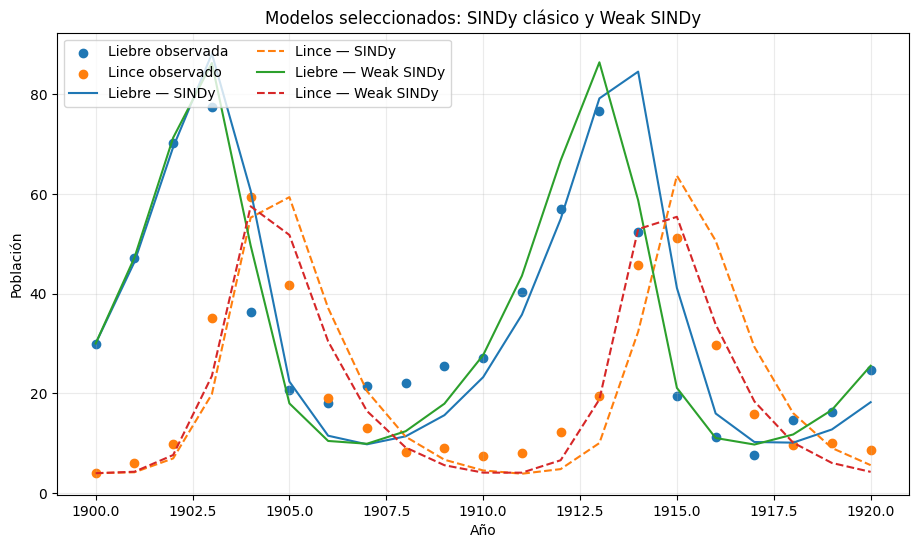

In [45]:
fig,ax=plt.subplots(figsize=(11,6))
ax.scatter(years,hare,label="Liebre observada")
ax.scatter(years,lynx,label="Lince observado")

for label,e in [("SINDy",best_classic),("Weak SINDy",best_weak)]:
    ok,Y=safe_simulate(e["coefficients"],e["library_names"],t,X[0])
    if ok:
        ax.plot(years,Y[:,0],label=f"Liebre — {label}")
        ax.plot(years,Y[:,1],"--",label=f"Lince — {label}")

ax.set(xlabel="Año",ylabel="Población",
       title="Modelos seleccionados: SINDy clásico y Weak SINDy")
ax.legend(ncol=2); ax.grid(alpha=.25); plt.show()

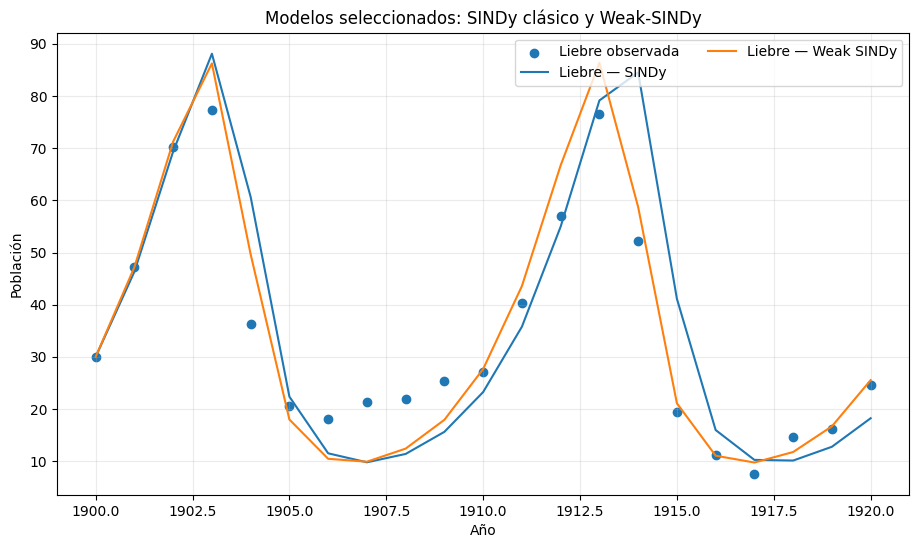

In [42]:
fig,ax=plt.subplots(figsize=(11,6))
ax.scatter(years,hare,label="Liebre observada")


for label,e in [("SINDy",best_classic),("Weak SINDy",best_weak)]:
    ok,Y=safe_simulate(e["coefficients"],e["library_names"],t,X[0])
    if ok:
        ax.plot(years,Y[:,0],label=f"Liebre — {label}")

ax.set(xlabel="Año",ylabel="Población",
       title="Modelos seleccionados: SINDy clásico y Weak-SINDy")
ax.legend(loc="upper right", ncol=2); ax.grid(alpha=.25); plt.show()

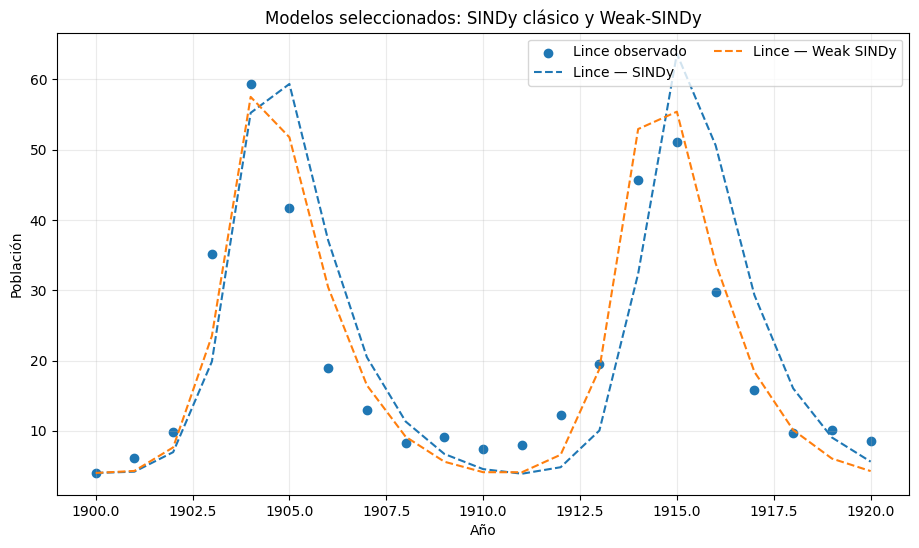

In [41]:
fig,ax=plt.subplots(figsize=(11,6))
ax.scatter(years,lynx,label="Lince observado")

for label,e in [("SINDy",best_classic),("Weak SINDy",best_weak)]:
    ok,Y=safe_simulate(e["coefficients"],e["library_names"],t,X[0])
    if ok:
        ax.plot(years,Y[:,1],"--",label=f"Lince — {label}")

ax.set(xlabel="Año",ylabel="Población",
       title="Modelos seleccionados: SINDy clásico y Weak-SINDy")
ax.legend(loc="upper right", ncol=2); ax.grid(alpha=.25); plt.show()